# ECG-PCG Dataset Preprocessing: Extract Clean 8-Second Chunks
This notebook processes the EPHNOGRAM dataset to extract only clean signals (both ECG and PCG marked as 'Good') and segments them into 8-second windows.

In [1]:
import numpy as np
import pandas as pd
import scipy.io as sio
import os
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Configuration

In [3]:
# Paths
DATA_DIR = r"E:\NUST MS Thesis\EPHONGRAM-Dataset\MAT"
OUTPUT_DIR = r"E:\NUST MS Thesis\New-Chunked Dataset"
METADATA_PATH = os.path.join(DATA_DIR, "ECGPCGSpreadsheet.csv")

# Parameters
CHUNK_DURATION = 8  # seconds
OVERLAP = 0  # seconds (no overlap initially; can be changed to 4 for 50% overlap)

# Create output directory
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Output directory: {OUTPUT_DIR}")

Output directory: E:\NUST MS Thesis\New-Chunked Dataset


## 2. Load Metadata and Filter Clean Signals

In [5]:
# Load metadata
metadata = pd.read_csv(METADATA_PATH)
print(f"Total records: {len(metadata)}")
print("\nMetadata columns:")
print(metadata.columns.tolist())

Total records: 69

Metadata columns:
['Record Name', 'Subject ID', 'Record Duration (min)', 'Age (years)', 'Gender', 'Recording Scenario', 'Num Channels', 'ECG Notes', 'PCG Notes', 'PCG2 Notes', 'AUX1 Notes', 'AUX2 Notes', 'Database Housekeeping']


In [7]:
# Display first few rows
metadata.head(10)

,Record Name,Subject ID,Record Duration (min),Age (years),Gender,Recording Scenario,Num Channels,ECG Notes,PCG Notes,PCG2 Notes,AUX1 Notes,AUX2 Notes,Database Housekeeping
0,ECGPCG0001,S023,30.0,NaN,Male,Exercise: pedaling a stationary bicycle,2,Good,Good,NaN,NaN,NaN,Replaced file ID 01
1,ECGPCG0002,S024,30.0,NaN,Male,Exercise: pedaling a stationary bicycle,2,Good; occasional saturation,Good,NaN,NaN,NaN,Replaced file ID 02
2,ECGPCG0003,S003,0.5,28.0,Male,Rest: sitting on armchair,2,Good,Good,NaN,NaN,NaN,Replaced file ID 03 (PG)
3,ECGPCG0004,S004,0.5,26.0,Male,Rest: sitting on armchair,5,Good,Occasional burst powerline noise,Quantization noise level,Quantization noise level,Quantization noise level,NaN
4,ECGPCG0005,S005,0.5,23.0,Male,Rest: sitting on armchair,5,Good,Occasional burst powerline noise,Quantization noise level,Quantization noise level,Quantization noise level,NaN
5,ECGPCG0006,S006,0.5,23.0,Male,Rest: sitting on armchair,5,Good,Good,Quantization noise level,Quantization noise level,Quantization noise level,NaN
6,ECGPCG0007,S007,0.5,27.0,Male,Rest: sitting on armchair,5,Good,Good,Quantization noise level,Quantization noise level,Quantization noise level,NaN
7,ECGPCG0008,S008,0.5,NaN,Male,Rest: sitting on armchair,5,Good,Good,Quantization noise level,Quantization noise level,Quantization noise level,NaN
8,ECGPCG0009,S009,0.5,25.0,Male,Rest: sitting on armchair,5,Good,Good,Quantization noise level,Quantization noise level,Quantization noise level,NaN
9,ECGPCG0010,S001,30.0,26.0,Male,Rest: sitting on armchair,2,Good,Good,NaN,NaN,NaN,NaN


In [9]:
# Filter only clean signals (both ECG and PCG = 'Good')
clean_signals = metadata[
    (metadata['ECG Notes'] == 'Good') & 
    (metadata['PCG Notes'] == 'Good')
].copy()

print(f"\nClean signals (ECG='Good' AND PCG='Good'): {len(clean_signals)} out of {len(metadata)}")
print(f"Percentage: {len(clean_signals)/len(metadata)*100:.1f}%")

# Display clean records
print("\nClean record IDs:")
print(clean_signals['Record Name'].tolist())


Clean signals (ECG='Good' AND PCG='Good'): 29 out of 69
Percentage: 42.0%

Clean record IDs:
['ECGPCG0001', 'ECGPCG0003', 'ECGPCG0006', 'ECGPCG0007', 'ECGPCG0008', 'ECGPCG0009', 'ECGPCG0010', 'ECGPCG0011', 'ECGPCG0013', 'ECGPCG0015', 'ECGPCG0016', 'ECGPCG0023', 'ECGPCG0029', 'ECGPCG0031', 'ECGPCG0032', 'ECGPCG0033', 'ECGPCG0034', 'ECGPCG0036', 'ECGPCG0040', 'ECGPCG0042', 'ECGPCG0043', 'ECGPCG0050', 'ECGPCG0055', 'ECGPCG0060', 'ECGPCG0061', 'ECGPCG0062', 'ECGPCG0064', 'ECGPCG0066', 'ECGPCG0067']


In [11]:
# Show distribution by recording scenario
print("\nClean signals by recording scenario:")
print(clean_signals['Recording Scenario'].value_counts())


Clean signals by recording scenario:
Recording Scenario
Rest: sitting on armchair                          8
Exercise: pedaling a stationary bicycle            6
Exercise: bicycle stress test                      6
Rest: laying on bed                                4
Exercise: walking at constant speed (3.7 km/h)     3
Exercise: Bruce protocol treadmill stress test     2
Name: count, dtype: int64


## 3. Inspect Sample .mat File Structure

In [13]:
# Load a sample file to understand structure
sample_file = os.path.join(DATA_DIR, clean_signals.iloc[0]['Record Name'] + '.mat')
print(f"Loading sample file: {sample_file}")

sample_data = sio.loadmat(sample_file)

# Display keys
print("\nKeys in .mat file:")
for key in sample_data.keys():
    if not key.startswith('__'):
        print(f"  {key}: {type(sample_data[key])}, shape: {sample_data[key].shape if hasattr(sample_data[key], 'shape') else 'N/A'}")

Loading sample file: E:\NUST MS Thesis\EPHONGRAM-Dataset\MAT\ECGPCG0001.mat

Keys in .mat file:
  ECG: <class 'numpy.ndarray'>, shape: (1, 14400000)
  PCG: <class 'numpy.ndarray'>, shape: (1, 14400000)
  fs: <class 'numpy.ndarray'>, shape: (1, 1)


In [15]:
# Identify the data structure
# Based on EPHNOGRAM documentation, typical structure is:
# - 'ecg': ECG signal
# - 'pcg': PCG signal  
# - 'fs': sampling frequency
# Let's check actual key names

data_keys = [k for k in sample_data.keys() if not k.startswith('__')]
print(f"\nData keys: {data_keys}")

# Try to identify ECG, PCG, and fs
for key in data_keys:
    data = sample_data[key]
    if hasattr(data, 'shape'):
        print(f"\n{key}:")
        print(f"  Shape: {data.shape}")
        print(f"  Dtype: {data.dtype}")
        if data.size < 10:
            print(f"  Value: {data}")
        else:
            print(f"  Min: {np.min(data):.4f}, Max: {np.max(data):.4f}, Mean: {np.mean(data):.4f}")


Data keys: ['ECG', 'PCG', 'fs']

ECG:
  Shape: (1, 14400000)
  Dtype: float64
  Min: -0.5972, Max: 0.7988, Mean: 0.0041

PCG:
  Shape: (1, 14400000)
  Dtype: float64
  Min: -0.8359, Max: 0.9995, Mean: -0.0008

fs:
  Shape: (1, 1)
  Dtype: uint16
  Value: [[8000]]


## 4. Visualize Sample ECG and PCG

In [ ]:
# Extract signals (adjust key names based on output above)
# Common patterns: 'ecg'/'ECG', 'pcg'/'PCG', 'fs'/'Fs'
# Let's try to auto-detect

def extract_signals(mat_data):
    """Extract ECG, PCG, and fs from .mat file"""
    keys = [k for k in mat_data.keys() if not k.startswith('__')]
    
    # Find fs (usually a scalar)
    fs = None
    for key in keys:
        if 'fs' in key.lower() and mat_data[key].size == 1:
            fs = float(mat_data[key].flatten()[0])
            break
    
    # Find ECG and PCG (usually arrays)
    # CRITICAL FIX: Use exact key matching to avoid confusing PCG with PCG2
    ecg, pcg = None, None
    
    # First, try exact key names (case-insensitive)
    key_upper = {k.upper(): k for k in keys}
    
    if 'ECG' in key_upper and mat_data[key_upper['ECG']].size > 100:
        ecg = mat_data[key_upper['ECG']].flatten()
    
    # IMPORTANT: Match 'PCG' exactly, NOT 'PCG2' or other variants
    if 'PCG' in key_upper and mat_data[key_upper['PCG']].size > 100:
        pcg = mat_data[key_upper['PCG']].flatten()
    
    # If exact match fails, try flexible matching but exclude PCG2, AUX, etc.
    if ecg is None or pcg is None:
        for key in keys:
            if ecg is None and key.upper() == 'ECG' and mat_data[key].size > 100:
                ecg = mat_data[key].flatten()
            # Match only 'PCG', not 'PCG2' or 'PCGX'
            elif pcg is None and key.upper() == 'PCG' and mat_data[key].size > 100:
                pcg = mat_data[key].flatten()
    
    # If keys don't match, assume structure from documentation
    # EPHNOGRAM has columns: [ECG, PCG] in a single array sometimes
    if ecg is None or pcg is None:
        for key in keys:
            if mat_data[key].size > 100:
                data_array = mat_data[key]
                if len(data_array.shape) == 2 and data_array.shape[1] == 2:
                    ecg = data_array[:, 0]
                    pcg = data_array[:, 1]
                    break
    
    return ecg, pcg, fs

# Test extraction
ecg, pcg, fs = extract_signals(sample_data)
print(f"\nExtracted signals:")
print(f"  ECG shape: {ecg.shape if ecg is not None else 'Not found'}")
print(f"  PCG shape: {pcg.shape if pcg is not None else 'Not found'}")
print(f"  Sampling frequency: {fs} Hz" if fs else "  Sampling frequency: Not found")

if ecg is not None and pcg is not None and fs is not None:
    duration = len(ecg) / fs
    print(f"  Signal duration: {duration:.2f} seconds ({duration/60:.2f} minutes)")

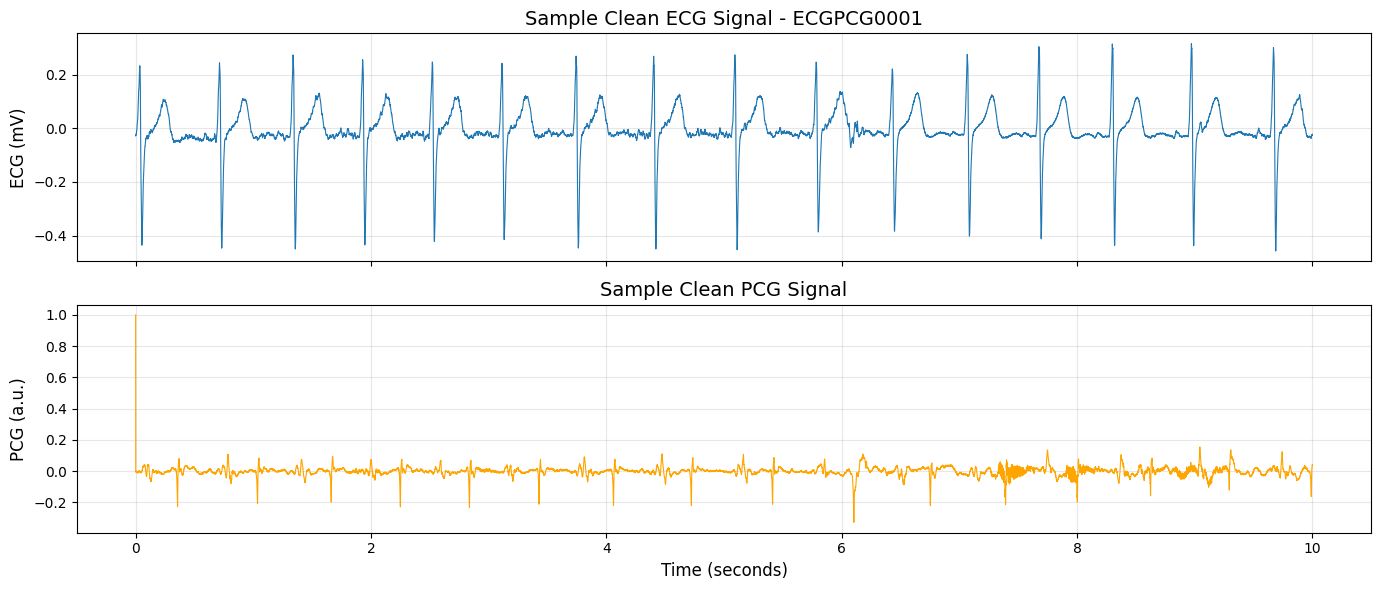


Visualized first 10.0 seconds of synchronized ECG-PCG signals


In [19]:
# Visualize first 10 seconds
if ecg is not None and pcg is not None and fs is not None:
    plot_duration = min(10, len(ecg)/fs)  # 10 seconds or full signal
    plot_samples = int(plot_duration * fs)
    
    time = np.arange(plot_samples) / fs
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    
    axes[0].plot(time, ecg[:plot_samples], linewidth=0.8)
    axes[0].set_ylabel('ECG (mV)', fontsize=12)
    axes[0].set_title(f'Sample Clean ECG Signal - {clean_signals.iloc[0]["Record Name"]}', fontsize=14)
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(time, pcg[:plot_samples], linewidth=0.8, color='orange')
    axes[1].set_ylabel('PCG (a.u.)', fontsize=12)
    axes[1].set_xlabel('Time (seconds)', fontsize=12)
    axes[1].set_title('Sample Clean PCG Signal', fontsize=14)
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nVisualized first {plot_duration:.1f} seconds of synchronized ECG-PCG signals")
else:
    print("\nError: Could not extract signals. Please check .mat file structure manually.")

## 5. Create 8-Second Chunks from Clean Signals

In [21]:
def create_chunks(ecg, pcg, fs, chunk_duration=8, overlap=0):
    """
    Split signals into fixed-duration chunks
    
    Parameters:
    - ecg, pcg: 1D arrays of signals
    - fs: sampling frequency (Hz)
    - chunk_duration: duration of each chunk (seconds)
    - overlap: overlap between consecutive chunks (seconds)
    
    Returns:
    - List of (ecg_chunk, pcg_chunk) tuples
    """
    chunk_samples = int(chunk_duration * fs)
    stride_samples = int((chunk_duration - overlap) * fs)
    
    chunks = []
    
    for start in range(0, len(ecg) - chunk_samples + 1, stride_samples):
        end = start + chunk_samples
        ecg_chunk = ecg[start:end]
        pcg_chunk = pcg[start:end]
        
        # Ensure both chunks have same length
        if len(ecg_chunk) == chunk_samples and len(pcg_chunk) == chunk_samples:
            chunks.append((ecg_chunk, pcg_chunk))
    
    return chunks

# Test chunking on sample
if ecg is not None and pcg is not None and fs is not None:
    test_chunks = create_chunks(ecg, pcg, fs, CHUNK_DURATION, OVERLAP)
    print(f"\nTest chunking results:")
    print(f"  Original signal duration: {len(ecg)/fs:.2f} seconds")
    print(f"  Chunk duration: {CHUNK_DURATION} seconds")
    print(f"  Overlap: {OVERLAP} seconds")
    print(f"  Number of chunks created: {len(test_chunks)}")
    print(f"  Each chunk has {len(test_chunks[0][0])} samples ({len(test_chunks[0][0])/fs:.2f} seconds)")


Test chunking results:
  Original signal duration: 1800.00 seconds
  Chunk duration: 8 seconds
  Overlap: 0 seconds
  Number of chunks created: 225
  Each chunk has 64000 samples (8.00 seconds)


## 6. Process All Clean Files and Save Chunks

In [23]:
def process_all_clean_files(clean_records_df, data_dir, output_dir, chunk_duration=8, overlap=0):
    """
    Process all clean .mat files and save chunks
    
    Saved format: .npz files containing:
    - 'ecg': ECG chunk
    - 'pcg': PCG chunk
    - 'fs': sampling frequency
    - 'source_file': original filename
    - 'chunk_index': chunk number within the file
    - 'subject_id': subject ID
    - 'scenario': recording scenario
    """
    
    total_chunks = 0
    processing_log = []
    
    print(f"Processing {len(clean_records_df)} clean files...\n")
    
    for idx, row in tqdm(clean_records_df.iterrows(), total=len(clean_records_df)):
        record_name = row['Record Name']
        subject_id = row['Subject ID']
        scenario = row['Recording Scenario']
        
        mat_file = os.path.join(data_dir, record_name + '.mat')
        
        if not os.path.exists(mat_file):
            print(f"Warning: File not found - {mat_file}")
            continue
        
        try:
            # Load .mat file
            mat_data = sio.loadmat(mat_file)
            ecg, pcg, fs = extract_signals(mat_data)
            
            if ecg is None or pcg is None or fs is None:
                print(f"Warning: Could not extract signals from {record_name}")
                continue
            
            # Create chunks
            chunks = create_chunks(ecg, pcg, fs, chunk_duration, overlap)
            
            # Save each chunk
            for chunk_idx, (ecg_chunk, pcg_chunk) in enumerate(chunks):
                # Filename format: {RecordName}_chunk{idx:03d}.npz
                chunk_filename = f"{record_name}_chunk{chunk_idx:03d}.npz"
                chunk_path = os.path.join(output_dir, chunk_filename)
                
                # Save as .npz
                np.savez(
                    chunk_path,
                    ecg=ecg_chunk,
                    pcg=pcg_chunk,
                    fs=fs,
                    source_file=record_name,
                    chunk_index=chunk_idx,
                    subject_id=subject_id,
                    scenario=scenario
                )
                
                total_chunks += 1
            
            # Log processing
            processing_log.append({
                'record_name': record_name,
                'subject_id': subject_id,
                'scenario': scenario,
                'duration_sec': len(ecg) / fs,
                'num_chunks': len(chunks),
                'fs': fs
            })
            
        except Exception as e:
            print(f"Error processing {record_name}: {str(e)}")
            continue
    
    # Save processing log
    log_df = pd.DataFrame(processing_log)
    log_path = os.path.join(output_dir, 'processing_log.csv')
    log_df.to_csv(log_path, index=False)
    
    print(f"\n{'='*60}")
    print(f"Processing complete!")
    print(f"{'='*60}")
    print(f"Total files processed: {len(processing_log)}")
    print(f"Total chunks created: {total_chunks}")
    print(f"Average chunks per file: {total_chunks/len(processing_log):.1f}")
    print(f"Output directory: {output_dir}")
    print(f"Processing log saved: {log_path}")
    
    return log_df, total_chunks

In [25]:
# Run the processing
log_df, total_chunks = process_all_clean_files(
    clean_records_df=clean_signals,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
    chunk_duration=CHUNK_DURATION,
    overlap=OVERLAP
)

Processing 29 clean files...



100%|██████████████████████████████████████████████████████████████████████████████████| 29/29 [00:56<00:00,  1.96s/it]


Processing complete!
Total files processed: 29
Total chunks created: 5193
Average chunks per file: 179.1
Output directory: E:\NUST MS Thesis\New-Chunked Dataset
Processing log saved: E:\NUST MS Thesis\New-Chunked Dataset\processing_log.csv


## 7. Dataset Statistics and Validation

In [27]:
# Display processing log
print("Processing Log Summary:")
print(log_df)

Processing Log Summary:
   record_name subject_id                                         scenario  \
0   ECGPCG0001       S023          Exercise: pedaling a stationary bicycle   
1   ECGPCG0003       S003                        Rest: sitting on armchair   
2   ECGPCG0006       S006                        Rest: sitting on armchair   
3   ECGPCG0007       S007                        Rest: sitting on armchair   
4   ECGPCG0008       S008                        Rest: sitting on armchair   
5   ECGPCG0009       S009                        Rest: sitting on armchair   
6   ECGPCG0010       S001                        Rest: sitting on armchair   
7   ECGPCG0011       S010                        Rest: sitting on armchair   
8   ECGPCG0013       S002                              Rest: laying on bed   
9   ECGPCG0015       S012                              Rest: laying on bed   
10  ECGPCG0016       S013                              Rest: laying on bed   
11  ECGPCG0023       S006               

In [29]:
# Statistics
print("\nDataset Statistics:")
print(f"  Total subjects: {log_df['subject_id'].nunique()}")
print(f"  Total recordings: {len(log_df)}")
print(f"  Total 8-second chunks: {total_chunks}")
print(f"\nChunks per scenario:")
print(log_df.groupby('scenario')['num_chunks'].sum().sort_values(ascending=False))


Dataset Statistics:
  Total subjects: 20
  Total recordings: 29
  Total 8-second chunks: 5193

Chunks per scenario:
scenario
Exercise: bicycle stress test                      1350
Exercise: pedaling a stationary bicycle            1350
Rest: laying on bed                                 900
Exercise: walking at constant speed (3.7 km/h)      675
Rest: sitting on armchair                           468
Exercise: Bruce protocol treadmill stress test      450
Name: num_chunks, dtype: int64


In [ ]:
# Validate a random saved chunk
import glob

saved_chunks = glob.glob(os.path.join(OUTPUT_DIR, '*.npz'))
print(f"\nFound {len(saved_chunks)} saved chunk files")

if len(saved_chunks) > 0:
    # Load random chunk
    random_chunk_path = np.random.choice(saved_chunks)
    print(f"\nValidating random chunk: {os.path.basename(random_chunk_path)}")
    
    chunk_data = np.load(random_chunk_path)
    
    print(f"\nChunk contents:")
    for key in chunk_data.files:
        value = chunk_data[key]
        if isinstance(value, np.ndarray):
            print(f"  {key}: shape={value.shape}, dtype={value.dtype}")
        else:
            print(f"  {key}: {value}")
    
    # Visualize the chunk
    ecg_chunk = chunk_data['ecg']
    pcg_chunk = chunk_data['pcg']
    fs_chunk = float(chunk_data['fs'])
    
    time = np.arange(len(ecg_chunk)) / fs_chunk
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    
    axes[0].plot(time, ecg_chunk, linewidth=0.8)
    axes[0].set_ylabel('ECG', fontsize=11)
    axes[0].set_title(f'Saved 8-Second Chunk - {os.path.basename(random_chunk_path)}', fontsize=13)
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(time, pcg_chunk, linewidth=0.8, color='orange')
    axes[1].set_ylabel('PCG', fontsize=11)
    axes[1].set_xlabel('Time (seconds)', fontsize=11)
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"\nChunk validation successful!")
    print(f"Duration: {len(ecg_chunk)/fs_chunk:.2f} seconds")
    print(f"Sampling rate: {fs_chunk} Hz")

## 8. Train/Validation/Test Split Recommendation

In [ ]:
# Subject-level split (to avoid data leakage)
from sklearn.model_selection import train_test_split

unique_subjects = log_df['subject_id'].unique()
print(f"Total unique subjects: {len(unique_subjects)}")

# Split: 70% train, 15% val, 15% test
train_subjects, temp_subjects = train_test_split(unique_subjects, test_size=0.3, random_state=42)
val_subjects, test_subjects = train_test_split(temp_subjects, test_size=0.5, random_state=42)

print(f"\nSubject split:")
print(f"  Train: {len(train_subjects)} subjects")
print(f"  Validation: {len(val_subjects)} subjects")
print(f"  Test: {len(test_subjects)} subjects")

# Count chunks per split
train_chunks = log_df[log_df['subject_id'].isin(train_subjects)]['num_chunks'].sum()
val_chunks = log_df[log_df['subject_id'].isin(val_subjects)]['num_chunks'].sum()
test_chunks = log_df[log_df['subject_id'].isin(test_subjects)]['num_chunks'].sum()

print(f"\nChunk distribution:")
print(f"  Train: {train_chunks} chunks ({train_chunks/total_chunks*100:.1f}%)")
print(f"  Validation: {val_chunks} chunks ({val_chunks/total_chunks*100:.1f}%)")
print(f"  Test: {test_chunks} chunks ({test_chunks/total_chunks*100:.1f}%)")

# Save split information
split_info = {
    'train_subjects': train_subjects.tolist(),
    'val_subjects': val_subjects.tolist(),
    'test_subjects': test_subjects.tolist()
}

import json
split_path = os.path.join(OUTPUT_DIR, 'train_val_test_split.json')
with open(split_path, 'w') as f:
    json.dump(split_info, f, indent=2)

print(f"\nSplit information saved to: {split_path}")

## Summary

**Data Format Recommendation:**
- **Primary:** Time-domain (raw waveform) saved as `.npz` files ✓
- **Advantages:** Preserves complete morphological information, direct 1D processing, easy evaluation
- **For novelty:** Consider adding frequency-domain auxiliary loss during model training

**Dataset Created:**
- Clean signals only (ECG='Good' AND PCG='Good')
- 8-second chunks with configurable overlap
- Saved in efficient `.npz` format with metadata
- Subject-level train/val/test split to prevent data leakage

**Next Steps:**
1. Review processing log and statistics
2. Implement data loader for model training
3. Design baseline model architecture (SigGAN-style)
4. Implement evaluation metrics (SNR, PSNR, correlation, etc.)